# LLM-BLM 元の S&P500 との比較ノート

`LLM-BLM/data/blm.sqlite` に保存した比率（`portfolio_weights`）を、**元の S&P500（時価総額加重）** と比べるノートです。

1. 比べる計算の一覧
2. 累積リターンの推移
3. 元の S&P500 との差（月ごと）
4. 成績表（全期間・前半・後半）
5. 比率の集中の推移
6. ある判断日の比率を、元の S&P500 と並べる
7. 直した設定と、元の設定の比較
8. LLM の予想と、実際のリターン

**使い方：** 下の「設定」のセルで、比べる計算や日付を変えて、上から順に実行します。カーネルは `LLM-BLM/.venv` を選んでください。

**読むときの注意：** 最適化した戦略は、今の設定では1〜数銘柄に集中しています。リターンの数字は、たまたま選ばれた銘柄の値動きを映しているだけで、戦略の良し悪しは判断できません（`LLM-BLM_段階1の結果.html`）。

## 0. 設定

In [2]:
from pathlib import Path
import sqlite3
import sys

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd

sys.path.insert(0, "LLM-BLM")                       # blm/evaluation.py の指標の計算を使う
from blm.evaluation import performance, turnover, effective_holdings

DB_PATH = Path("LLM-BLM/data/blm.sqlite")           # このノート（工房直下）から見た DB の場所

# 比べる計算（portfolio_runs.portfolio_id）。None にすると、戦略ごとに一番新しい計算を使う
PORTFOLIO_IDS = None
BENCHMARK = "market_cap"                            # 比べる相手：元の S&P500（時価総額加重）
SPLIT = 15                                          # 前半の月数（残りが後半）
WEIGHT_DATE = "2025-06-30"                          # 6章で比率を見る判断日
TOP_N = 10                                          # 6章で表示する銘柄数

NAMES = {
    "market_cap": "時価総額加重（元の S&P500）",
    "equal_weight": "等金額",
    "mean_variance": "平均分散",
    "black_litterman": "BL（直した設定）",
    "black_litterman_original": "BL（元の設定）",
}
COLORS = {
    "market_cap": "#2a78d6", "equal_weight": "#1baf7a", "mean_variance": "#eda100",
    "black_litterman": "#eb6834", "black_litterman_original": "#4a3aa7",
}

plt.rcParams["font.family"] = ["Hiragino Sans", "sans-serif"]
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["figure.dpi"] = 110

conn = sqlite3.connect(f"file:{DB_PATH}?mode=ro", uri=True)   # 読み取り専用で開く


def q(sql, params=()):
    return pd.read_sql(sql, conn, params=params)


def show(df, formats=None, index=True):
    """表を見やすい書式で表示する。"""
    df = df.copy()
    for col, fmt in (formats or {}).items():
        df[col] = df[col].map(lambda v: "" if pd.isna(v) else fmt.format(v))
    display(df if index else df.reset_index(drop=True))


def pct_axis(ax, digits=0):
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v * 100:.{digits}f}%"))

## 1. 比べる計算の一覧

In [3]:
runs = q("SELECT portfolio_id, strategy, llm_run_id, params, note, created_at FROM portfolio_runs")
if PORTFOLIO_IDS is None:
    runs = runs.sort_values("portfolio_id").groupby("strategy").tail(1)
else:
    runs = runs[runs.portfolio_id.isin(PORTFOLIO_IDS)]
runs = runs.sort_values("portfolio_id").set_index("portfolio_id")
STRATEGIES = list(runs.strategy)                    # このノートで比べる戦略（計算した順）
show(runs)

,strategy,llm_run_id,params,note,created_at
portfolio_id,,,,,
1,market_cap,NaN,"{""cov_window_days"": 252, ""min_history_ratio"": ...",段階1の最初の実行（論文と同じ tau、リスク回避度 2.5）,2026-10-10T12:07:56+00:00
2,equal_weight,NaN,"{""cov_window_days"": 252, ""min_history_ratio"": ...",段階1の最初の実行（論文と同じ tau、リスク回避度 2.5）,2026-10-10T12:07:56+00:00
3,mean_variance,NaN,"{""cov_window_days"": 252, ""covariance"": ""ledoit...",段階1の最初の実行（論文と同じ tau、リスク回避度 2.5）,2026-10-10T12:07:56+00:00
4,black_litterman,1.0,"{""cov_window_days"": 252, ""covariance"": ""ledoit...",段階1の最初の実行（論文と同じ tau、リスク回避度 2.5）,2026-10-10T12:07:56+00:00
5,black_litterman_original,1.0,"{""cov_window_days"": 252, ""covariance"": ""sample...",段階1の最初の実行（論文と同じ tau、リスク回避度 2.5）,2026-10-10T12:07:56+00:00
6,mean_variance_original,NaN,"{""cov_window_days"": 252, ""covariance"": ""sample...",元論文の平均分散（baselines.py と同じ計算）,2026-10-11T13:25:15+00:00


In [4]:
marks = ",".join(str(i) for i in runs.index)
ret = q(f"SELECT portfolio_id, as_of_date, end_date, n_holdings, period_return FROM portfolio_returns WHERE portfolio_id IN ({marks})")
R = ret.pivot(index="as_of_date", columns="portfolio_id", values="period_return")
R.columns = runs.strategy[R.columns]                # 行 = 判断日、列 = 戦略、値 = 翌月のリターン
END = ret.drop_duplicates("as_of_date").set_index("as_of_date").end_date          # 判断日 → 保有の終わり

weights = q(f"SELECT portfolio_id, as_of_date, symbol, weight FROM portfolio_weights WHERE portfolio_id IN ({marks})")
W = {runs.strategy[pid]: g.pivot(index="as_of_date", columns="symbol", values="weight") for pid, g in weights.groupby("portfolio_id")}

# 無リスク金利（3か月物の国債利回り。年率のパーセントを月次の小数に直す）と、実際の S&P500 指数（配当なし）
irx = q("SELECT date, close FROM prices WHERE symbol = '^IRX'").set_index("date")["close"]
RF = irx.reindex(R.index, method="ffill") / 100 / 12
gspc = q("SELECT date, close FROM prices WHERE symbol = '^GSPC'").set_index("date")["close"]
GSPC = pd.Series([gspc[END[d]] / gspc[d] - 1 for d in R.index], index=R.index)

print(f"判断日: {R.index[0]} 〜 {R.index[-1]}（{len(R)} か月）")
print(f"保有の終わり: {END.iloc[0]} 〜 {END.iloc[-1]}")
print(f"対象の銘柄数（月の平均）: {W[BENCHMARK].notna().sum(axis=1).mean():.0f}")

判断日: 2024-03-28 〜 2026-08-31（30 か月）
保有の終わり: 2024-04-30 〜 2026-09-30
対象の銘柄数（月の平均）: 488


## 2. 累積リターンの推移

判断日の終値で買い、翌月の最後の取引日まで持ち続けた場合の、1 を投資したときの価値です（配当込み、売買コストなし）。縦軸は対数目盛です。

KeyError: 'mean_variance_original'

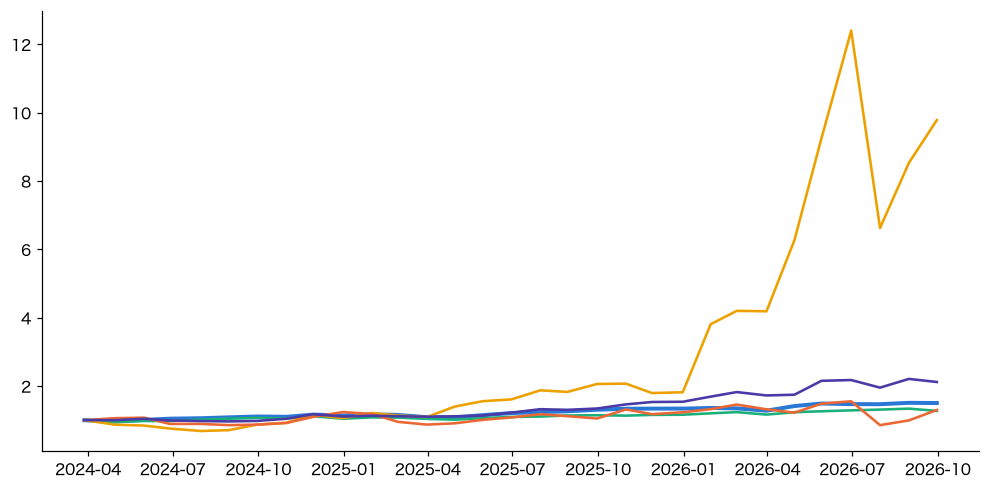

In [5]:
dates = pd.to_datetime([R.index[0]] + list(END[R.index]))
fig, ax = plt.subplots(figsize=(11, 5.2))
last = {}
for s in STRATEGIES:
    wealth = np.r_[1, (1 + R[s]).cumprod().values]
    last[s] = wealth[-1]
    ax.plot(dates, wealth, color=COLORS[s], lw=2.6 if s == BENCHMARK else 1.7)
ax.plot(dates, np.r_[1, (1 + GSPC).cumprod().values], color="#888", lw=1.2, ls="--")
ax.set_yscale("log")
ticks = [t for t in [0.5, 1, 2, 5, 10, 20] if min(last.values()) / 2 < t < max(last.values()) * 2]
ax.set_yticks(ticks); ax.set_yticklabels([str(t) for t in ticks]); ax.minorticks_off()
prev = 0
for s, v in sorted(last.items(), key=lambda kv: kv[1]):         # 線の右端に名前を置く（重なる場合は少しずらす）
    y = max(v, prev * 1.14) if prev else v; prev = y
    ax.annotate(f"{NAMES[s]}  {v:.2f}", (dates[-1], y), xytext=(8, 0), textcoords="offset points", va="center", color=COLORS[s], fontsize=10, fontweight="bold")
ax.axvline(pd.Timestamp(END[R.index[SPLIT - 1]]), color="#888", lw=1, ls=":")
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7])); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.set_ylabel("1 を投資した場合の価値（対数目盛）"); ax.grid(axis="y", color="#ddd", lw=0.6)
ax.set_title("累積リターン（灰色の破線：実際の S&P500 指数・配当なし、点線：前半と後半の境目）", loc="left", fontsize=11)
fig.subplots_adjust(right=0.74)
plt.show()

**見るポイント**
- **青の太線（時価総額加重）と灰色の破線（実際の指数）がほぼ重なる**こと。差は配当の分で、DB と計算が正しいことの確認になります。
- 最適化した戦略の線が大きく上下するのは、少数の銘柄に集中しているためです。

## 3. 元の S&P500 との差（月ごと）

各戦略の月次リターンから、元の S&P500（時価総額加重）の月次リターンを引いたものです。0 より上の月は、元の S&P500 を上回っています。

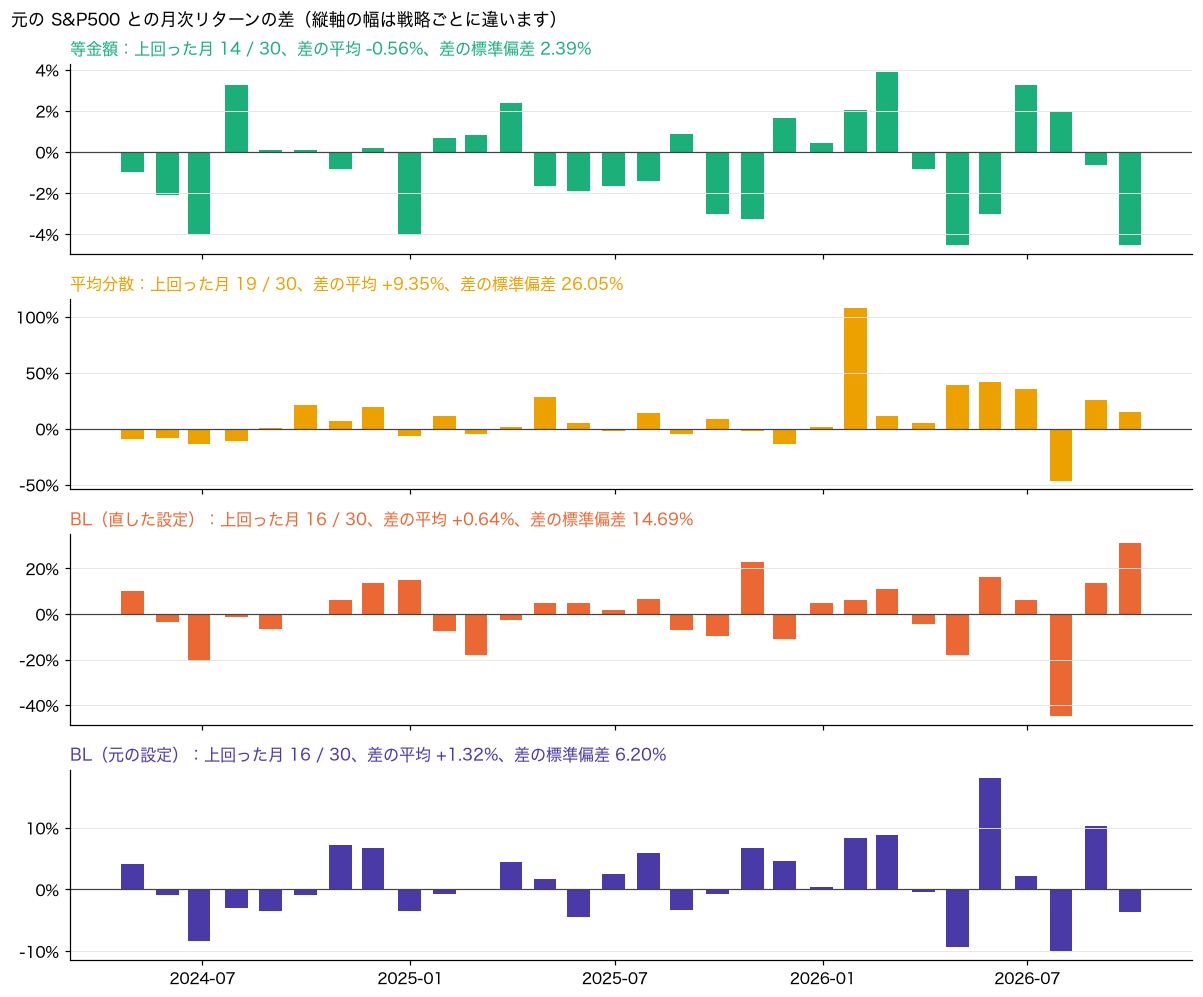

In [5]:
others = [s for s in STRATEGIES if s != BENCHMARK]
active = R[others].sub(R[BENCHMARK], axis=0)
x = pd.to_datetime(END[R.index].values)
fig, axes = plt.subplots(len(others), 1, figsize=(11, 2.3 * len(others)), sharex=True)
for ax, s in zip(np.atleast_1d(axes), others):
    ax.bar(x, active[s], width=20, color=COLORS[s])
    ax.axhline(0, color="#444", lw=0.8)
    pct_axis(ax)
    ax.grid(axis="y", color="#e5e5e5", lw=0.6)
    won = int((active[s] > 0).sum())
    ax.set_title(f"{NAMES[s]}：上回った月 {won} / {len(active)}、差の平均 {active[s].mean() * 100:+.2f}%、差の標準偏差 {active[s].std() * 100:.2f}%", loc="left", fontsize=10.5, color=COLORS[s])
np.atleast_1d(axes)[-1].xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7])); np.atleast_1d(axes)[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
fig.suptitle("元の S&P500 との月次リターンの差（縦軸の幅は戦略ごとに違います）", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
plt.show()

In [6]:
# 月ごとの数字（パーセント）
table = (R[STRATEGIES] * 100).round(1)
table.insert(0, "保有の終わり", END[R.index])
table = table.rename(columns=NAMES)
table["実際の指数（配当なし）"] = (GSPC * 100).round(1)
show(table)

strategy,保有の終わり,時価総額加重（元の S&P500）,等金額,平均分散,BL（直した設定）,BL（元の設定）,実際の指数（配当なし）
as_of_date,,,,,,,
2024-03-28,2024-04-30,-4.0,-5.0,-13.1,5.9,0.1,-4.2
2024-04-30,2024-05-31,5.0,2.9,-3.0,1.5,4.0,4.8
2024-05-31,2024-06-28,3.7,-0.3,-10.3,-17.0,-4.7,3.5
2024-06-28,2024-07-31,1.2,4.4,-9.6,0.0,-1.8,1.1
2024-07-31,2024-08-30,2.5,2.5,3.6,-4.0,-1.0,2.3
2024-08-30,2024-09-30,2.3,2.3,23.2,1.7,1.4,2.0
2024-09-30,2024-10-31,-0.8,-1.7,6.1,5.4,6.4,-1.0
2024-10-31,2024-11-29,6.0,6.2,25.3,19.7,12.7,5.7
2024-11-29,2024-12-31,-2.3,-6.3,-8.6,12.7,-5.7,-2.5


## 4. 成績表（全期間・前半・後半）

- **年率リスク：** 月次リターンの標準偏差を年率に直したもの
- **シャープレシオ：** （リターン − 無リスク金利）÷ リスク。無リスク金利は3か月物の国債利回り
- **元との差（年率）：** 元の S&P500 との月次の差の平均 × 12
- **ずれの大きさ（年率）：** 元の S&P500 との月次の差の標準偏差を年率に直したもの

In [7]:
def performance_table(index):
    rows = {}
    for s in STRATEGIES:
        rows[NAMES[s]] = performance(R.loc[index, s], RF[index], None if s == BENCHMARK else R.loc[index, BENCHMARK])
    rows["実際の指数（配当なし）"] = performance(GSPC[index], RF[index], R.loc[index, BENCHMARK])
    t = pd.DataFrame(rows).T
    t = t[["annual_return", "annual_volatility", "sharpe_ratio", "max_drawdown", "worst_month", "annual_active_return", "tracking_error", "months_above_benchmark"]]
    t.columns = ["年率リターン", "年率リスク", "シャープレシオ", "最大下落率", "最悪の月", "元との差（年率）", "ずれの大きさ（年率）", "上回った月"]
    return t

FORMATS = {"年率リターン": "{:+.1%}", "年率リスク": "{:.1%}", "シャープレシオ": "{:.2f}", "最大下落率": "{:+.1%}", "最悪の月": "{:+.1%}",
           "元との差（年率）": "{:+.1%}", "ずれの大きさ（年率）": "{:.1%}", "上回った月": "{:.0f}"}
for title, index in [(f"全期間（{len(R)} か月）", R.index), (f"前半（判断日 {R.index[0]} 〜 {R.index[SPLIT - 1]}）", R.index[:SPLIT]),
                     (f"後半（判断日 {R.index[SPLIT]} 〜 {R.index[-1]}）", R.index[SPLIT:])]:
    print(title)
    show(performance_table(index), FORMATS)

全期間（30 か月）


,年率リターン,年率リスク,シャープレシオ,最大下落率,最悪の月,元との差（年率）,ずれの大きさ（年率）,上回った月
時価総額加重（元の S&P500）,+17.7%,12.2%,1.06,-7.7%,-5.8%,,,
等金額,+10.1%,11.7%,0.52,-8.9%,-6.3%,-6.8%,8.3%,14
平均分散,+149.0%,93.7%,1.34,-46.6%,-46.6%,+112.2%,90.2%,19
BL（直した設定）,+11.0%,51.4%,0.40,-45.0%,-45.0%,+7.6%,50.9%,16
BL（元の設定）,+35.0%,23.5%,1.22,-10.2%,-10.2%,+15.8%,21.5%,16
実際の指数（配当なし）,+16.2%,12.1%,0.96,-7.8%,-5.8%,-1.3%,0.3%,6


前半（判断日 2024-03-28 〜 2025-05-30）


,年率リターン,年率リスク,シャープレシオ,最大下落率,最悪の月,元との差（年率）,ずれの大きさ（年率）,上回った月
時価総額加重（元の S&P500）,+16.3%,12.9%,0.88,-7.7%,-5.8%,,,
等金額,+7.7%,13.1%,0.27,-8.9%,-6.3%,-7.8%,7.1%,7
平均分散,+46.3%,47.4%,0.92,-21.4%,-13.1%,+32.5%,43.9%,8
BL（直した設定）,+6.4%,36.7%,0.22,-29.6%,-19.4%,-3.3%,35.5%,7
BL（元の設定）,+17.4%,16.6%,0.77,-7.4%,-5.7%,+1.4%,15.2%,7
実際の指数（配当なし）,+14.2%,12.7%,0.75,-7.8%,-5.8%,-1.8%,0.3%,2


後半（判断日 2025-06-30 〜 2026-08-31）


,年率リターン,年率リスク,シャープレシオ,最大下落率,最悪の月,元との差（年率）,ずれの大きさ（年率）,上回った月
時価総額加重（元の S&P500）,+19.1%,12.0%,1.21,-5.9%,-5.0%,,,
等金額,+12.6%,10.5%,0.83,-5.8%,-5.8%,-5.8%,9.6%,7
平均分散,+323.7%,121.5%,1.70,-46.6%,-46.6%,+192.0%,117.5%,11
BL（直した設定）,+15.9%,64.0%,0.52,-45.0%,-45.0%,+18.6%,63.9%,9
BL（元の設定）,+55.3%,28.7%,1.56,-10.2%,-10.2%,+30.2%,26.2%,9
実際の指数（配当なし）,+18.3%,11.9%,1.15,-5.9%,-5.1%,-0.7%,0.3%,4


## 5. 比率の集中の推移

**実質的な銘柄数** は、同じ集中度になる等金額の銘柄数です（1 ÷ 比率の2乗の合計）。500銘柄に等しく分ければ 500、1銘柄に全部入れれば 1 になります。元の S&P500 が約50なのは、上位の大型株の比率が大きいためです。

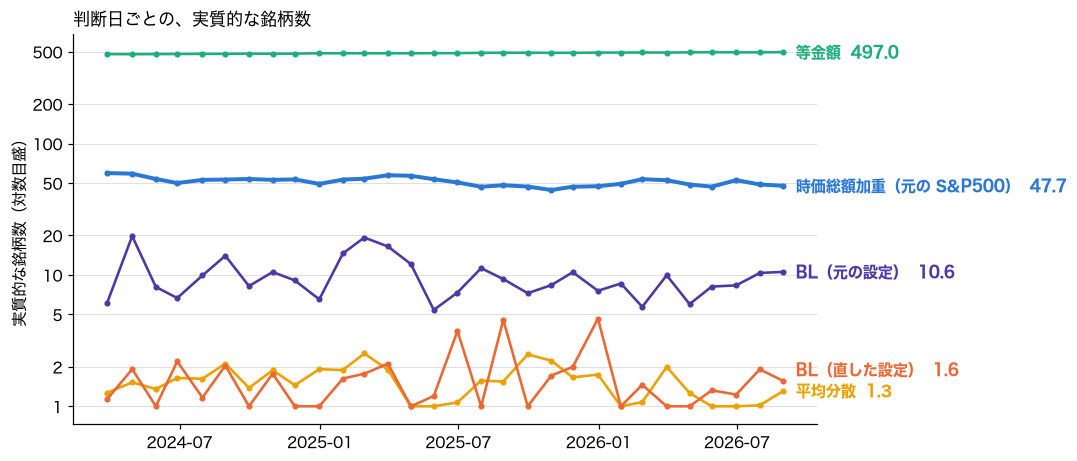

In [8]:
x = pd.to_datetime(R.index)
fig, ax = plt.subplots(figsize=(11, 4.6))
last = {}
for s in STRATEGIES:
    eff = 1 / (W[s].fillna(0) ** 2).sum(axis=1)
    last[s] = eff.iloc[-1]
    ax.plot(x, eff, color=COLORS[s], lw=2.6 if s == BENCHMARK else 1.7, marker="o", ms=3)
prev = 0
for s, v in sorted(last.items(), key=lambda kv: kv[1]):         # 線の右端に名前を置く（重なる場合は少しずらす）
    y = max(v, prev * 1.45) if prev else v; prev = y
    ax.annotate(f"{NAMES[s]}  {v:.1f}", (x[-1], y), xytext=(8, 0), textcoords="offset points", va="center", color=COLORS[s], fontsize=10, fontweight="bold")
ax.set_yscale("log"); ax.set_yticks([1, 2, 5, 10, 20, 50, 100, 200, 500]); ax.set_yticklabels(["1", "2", "5", "10", "20", "50", "100", "200", "500"]); ax.minorticks_off()
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7])); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.set_ylabel("実質的な銘柄数（対数目盛）"); ax.grid(axis="y", color="#ddd", lw=0.6)
ax.set_title("判断日ごとの、実質的な銘柄数", loc="left", fontsize=11)
fig.subplots_adjust(right=0.74)
plt.show()

In [9]:
summary = pd.DataFrame({NAMES[s]: {
    "実質的な銘柄数（平均）": effective_holdings(W[s]),
    "比率が 0.1% を超える銘柄数（平均）": (W[s] > 0.001).sum(axis=1).mean(),
    "最大の比率（平均）": W[s].max(axis=1).mean(),
    "毎月入れ替わる割合": turnover(W[s]),
    "元の S&P500 と重なる割合（平均）": np.minimum(W[s].fillna(0), W[BENCHMARK].fillna(0)).sum(axis=1).mean(),
} for s in STRATEGIES}).T
show(summary, {"実質的な銘柄数（平均）": "{:.1f}", "比率が 0.1% を超える銘柄数（平均）": "{:.0f}", "最大の比率（平均）": "{:.1%}", "毎月入れ替わる割合": "{:.0%}", "元の S&P500 と重なる割合（平均）": "{:.0%}"})

,実質的な銘柄数（平均）,比率が 0.1% を超える銘柄数（平均）,最大の比率（平均）,毎月入れ替わる割合,元の S&P500 と重なる割合（平均）
時価総額加重（元の S&P500）,51.5,184,7.1%,3%,100%
等金額,488.5,488,0.2%,0%,46%
平均分散,1.5,2,78.9%,24%,1%
BL（直した設定）,1.7,2,78.0%,100%,1%
BL（元の設定）,9.9,16,19.0%,96%,4%


**見るポイント**
- **「元の S&P500 と重なる割合」** は、両方が共通して持っている比率の合計です。100% なら元の S&P500 と同じ、0% なら全く別の銘柄を持っています。「比率を調整した」と言えるのは、この値が高い場合です。
- **「毎月入れ替わる割合」** が 100% に近い戦略は、毎月ほぼ全部を売って買い直しています。

## 6. ある判断日の比率を、元の S&P500 と並べる

「設定」の `WEIGHT_DATE` の判断日について、元の S&P500 の上位銘柄と、各戦略の上位銘柄を並べます。

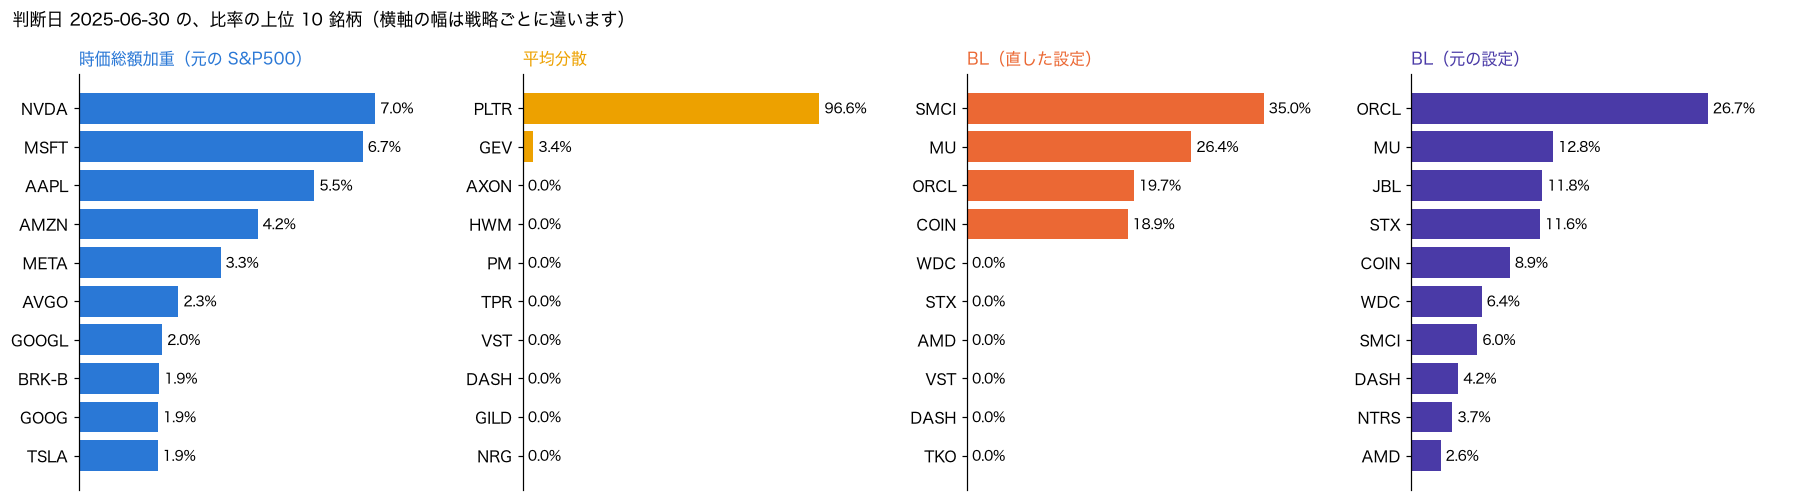

In [10]:
shown = [s for s in STRATEGIES if s != "equal_weight"]
fig, axes = plt.subplots(1, len(shown), figsize=(4.1 * len(shown), 4.6))
for ax, s in zip(np.atleast_1d(axes), shown):
    top = W[s].loc[WEIGHT_DATE].dropna().sort_values(ascending=False).head(TOP_N)[::-1]
    ax.barh(top.index, top.values, color=COLORS[s])
    for symbol, v in top.items():
        ax.text(v, symbol, f" {v * 100:.1f}%", va="center", fontsize=9)
    ax.set_xlim(0, top.max() * 1.25); ax.set_xticks([])
    ax.spines["bottom"].set_visible(False)
    ax.set_title(NAMES[s], loc="left", fontsize=10.5, color=COLORS[s])
fig.suptitle(f"判断日 {WEIGHT_DATE} の、比率の上位 {TOP_N} 銘柄（横軸の幅は戦略ごとに違います）", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
plt.show()

In [11]:
# 同じ判断日について、各戦略が持っている銘柄を1つの表にする（どれかで 1% を超える銘柄）
day = pd.DataFrame({NAMES[s]: W[s].loc[WEIGHT_DATE] for s in shown}).fillna(0)
day = day[(day > 0.01).any(axis=1)].sort_values(NAMES[BENCHMARK], ascending=False)
info = q("SELECT symbol, security, gics_sector FROM tickers").set_index("symbol")
day.insert(0, "セクター", info.gics_sector.reindex(day.index))
day.insert(0, "社名", info.security.reindex(day.index))
show(day, {NAMES[s]: "{:.1%}" for s in shown})

,社名,セクター,時価総額加重（元の S&P500）,平均分散,BL（直した設定）,BL（元の設定）
symbol,,,,,,
NVDA,Nvidia,Information Technology,7.0%,0.0%,0.0%,0.0%
MSFT,Microsoft,Information Technology,6.7%,0.0%,0.0%,0.0%
AAPL,Apple Inc.,Information Technology,5.5%,0.0%,0.0%,0.0%
AMZN,Amazon,Consumer Discretionary,4.2%,0.0%,0.0%,0.0%
META,Meta Platforms,Communication Services,3.3%,0.0%,0.0%,0.0%
AVGO,Broadcom,Information Technology,2.3%,0.0%,0.0%,0.0%
GOOGL,Alphabet Inc. (Class A),Communication Services,2.0%,0.0%,0.0%,0.0%
BRK-B,Berkshire Hathaway,Financials,1.9%,0.0%,0.0%,0.0%
GOOG,Alphabet Inc. (Class C),Communication Services,1.9%,0.0%,0.0%,0.0%


## 7. 直した設定と、元の設定の比較

同じ銘柄・同じ LLM の予想を使い、計算の方法だけが違います。

| | 直した設定 | 元の設定 |
|---|---|---|
| 共分散 | 過去1年の日次リターン、縮小推定 | 判断月の約20日分だけ |
| 市場の均衡 | 時価総額の比率から逆算 | 年率の金利を日次リターンから引く式 |
| 最適化 | 二次計画用の解法 | scipy の標準設定（最適解に届く前に止まる） |

In [12]:
if {"black_litterman", "black_litterman_original"} <= set(STRATEGIES):
    a, b = W["black_litterman"].fillna(0), W["black_litterman_original"].fillna(0)
    compare = pd.DataFrame({
        "保有の終わり": END[R.index],
        "直した設定：最大の銘柄": a.idxmax(axis=1), "直した設定：その比率": a.max(axis=1), "直した設定：リターン": R["black_litterman"],
        "元の設定：最大の銘柄": b.idxmax(axis=1), "元の設定：その比率": b.max(axis=1), "元の設定：銘柄数": (b > 0.001).sum(axis=1), "元の設定：リターン": R["black_litterman_original"],
        "2つが重なる割合": np.minimum(a, b).sum(axis=1), "元の S&P500 のリターン": R[BENCHMARK],
    })
    show(compare, {"直した設定：その比率": "{:.0%}", "直した設定：リターン": "{:+.1%}", "元の設定：その比率": "{:.0%}", "元の設定：リターン": "{:+.1%}",
                   "2つが重なる割合": "{:.0%}", "元の S&P500 のリターン": "{:+.1%}"})

,保有の終わり,直した設定：最大の銘柄,直した設定：その比率,直した設定：リターン,元の設定：最大の銘柄,元の設定：その比率,元の設定：銘柄数,元の設定：リターン,2つが重なる割合,元の S&P500 のリターン
as_of_date,,,,,,,,,,
2024-03-28,2024-04-30,FCX,94%,+5.9%,NRG,28%,14,+0.1%,14%,-4.0%
2024-04-30,2024-05-31,NEM,66%,+1.5%,NRG,9%,28,+4.0%,14%,+5.0%
2024-05-31,2024-06-28,FSLR,100%,-17.0%,IP,23%,12,-4.7%,10%,+3.7%
2024-06-28,2024-07-31,ADSK,49%,+0.0%,AVGO,22%,13,-1.8%,38%,+1.2%
2024-07-31,2024-08-30,MHK,92%,-4.0%,TSLA,18%,16,-1.0%,16%,+2.5%
2024-08-30,2024-09-30,FTNT,60%,+1.7%,CLX,12%,18,+1.4%,23%,+2.3%
2024-09-30,2024-10-31,VST,100%,+5.4%,UAL,17%,14,+6.4%,17%,-0.8%
2024-10-31,2024-11-29,UAL,68%,+19.7%,UAL,16%,18,+12.7%,23%,+6.0%
2024-11-29,2024-12-31,PLTR,100%,+12.7%,PLTR,17%,15,-5.7%,17%,-2.3%


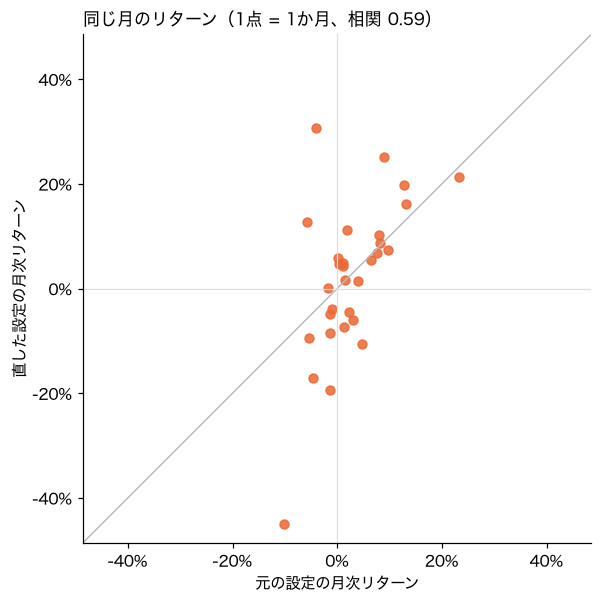

In [13]:
if {"black_litterman", "black_litterman_original"} <= set(STRATEGIES):
    fig, ax = plt.subplots(figsize=(6.2, 6))
    lim = max(R["black_litterman"].abs().max(), R["black_litterman_original"].abs().max()) * 1.08
    ax.plot([-lim, lim], [-lim, lim], color="#bbb", lw=1)
    ax.axhline(0, color="#ddd", lw=0.8); ax.axvline(0, color="#ddd", lw=0.8)
    ax.scatter(R["black_litterman_original"], R["black_litterman"], s=34, color=COLORS["black_litterman"], alpha=0.85)
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v * 100:.0f}%")); pct_axis(ax)
    ax.set_xlabel("元の設定の月次リターン"); ax.set_ylabel("直した設定の月次リターン")
    corr = R["black_litterman"].corr(R["black_litterman_original"])
    ax.set_title(f"同じ月のリターン（1点 = 1か月、相関 {corr:.2f}）", loc="left", fontsize=11)
    plt.show()

**見るポイント**
- 直した設定は、毎月1〜2銘柄にほぼ全額を入れています。元の設定は十数銘柄に分かれています。
- 元の設定が分かれて見えるのは、最適化が最適解に届く前に止まっているためです。同じ式を正しく解くと、4銘柄前後に集中します（`LLM-BLM_段階1の結果.html` の6章）。

## 8. LLM の予想と、実際のリターン

比率のもとになっている LLM の予想が、どれだけ当たっていたかを見ます。**順位相関** は、「予想が高い順」と「実際に上がった順」がどれだけ一致したかです（+1 で完全に一致、0 で無関係、−1 で正反対）。

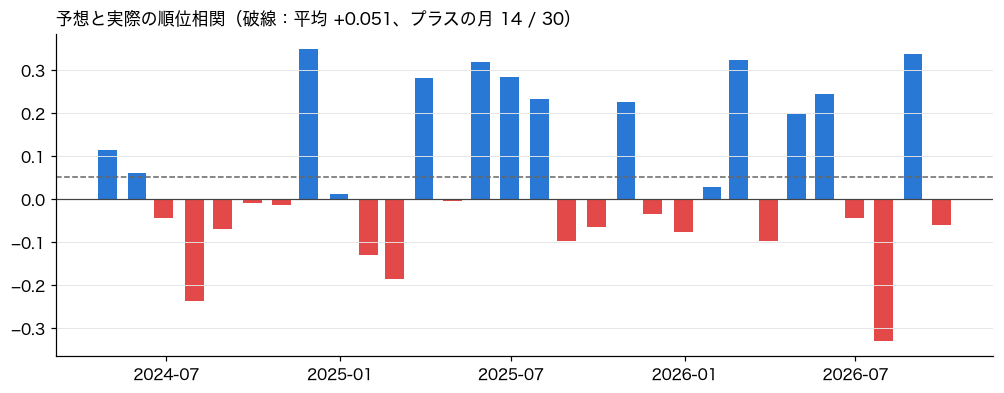

In [14]:
llm_run_id = int(runs.llm_run_id.dropna().iloc[0])
stats = q("SELECT as_of_date, symbol, mean_return FROM llm_view_stats WHERE run_id = ?", (llm_run_id,))
prices = q("SELECT symbol, date, adj_close FROM prices").pivot(index="date", columns="symbol", values="adj_close")
rows = []
for d in R.index:
    days = ((prices.index > d) & (prices.index <= END[d])).sum()
    realized = (prices.loc[END[d]] / prices.loc[d]) ** (1 / days) - 1          # 翌月の、1日あたりの平均リターン
    both = pd.concat([stats[stats.as_of_date == d].set_index("symbol").mean_return, realized.rename("realized")], axis=1, join="inner").dropna()
    rows.append({"判断日": d, "銘柄数": len(both), "予想の平均": both.mean_return.mean(), "実際の平均": both.realized.mean(),
                 "順位相関": both.mean_return.corr(both.realized, method="spearman")})
hit = pd.DataFrame(rows).set_index("判断日")

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar(pd.to_datetime(END[hit.index].values), hit["順位相関"], width=20, color=np.where(hit["順位相関"] > 0, "#2a78d6", "#e34948"))
ax.axhline(0, color="#444", lw=0.8); ax.axhline(hit["順位相関"].mean(), color="#666", lw=1, ls="--")
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7])); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.grid(axis="y", color="#e5e5e5", lw=0.6)
ax.set_title(f"予想と実際の順位相関（破線：平均 {hit['順位相関'].mean():+.3f}、プラスの月 {(hit['順位相関'] > 0).sum()} / {len(hit)}）", loc="left", fontsize=11)
plt.show()

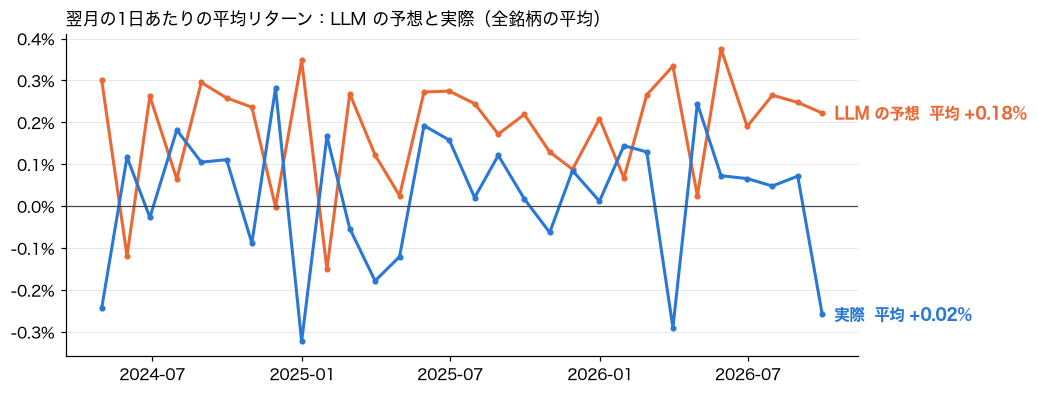

In [15]:
fig, ax = plt.subplots(figsize=(11, 3.8))
x = pd.to_datetime(END[hit.index].values)
ax.plot(x, hit["予想の平均"], color="#eb6834", lw=2, marker="o", ms=3)
ax.plot(x, hit["実際の平均"], color="#2a78d6", lw=2, marker="o", ms=3)
ax.axhline(0, color="#444", lw=0.8)
ax.annotate(f"LLM の予想  平均 {hit['予想の平均'].mean() * 100:+.2f}%", (x[-1], hit["予想の平均"].iloc[-1]), xytext=(8, 0), textcoords="offset points", va="center", color="#eb6834", fontsize=10, fontweight="bold")
ax.annotate(f"実際  平均 {hit['実際の平均'].mean() * 100:+.2f}%", (x[-1], hit["実際の平均"].iloc[-1]), xytext=(8, 0), textcoords="offset points", va="center", color="#2a78d6", fontsize=10, fontweight="bold")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v * 100:.1f}%"))
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7])); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.grid(axis="y", color="#e5e5e5", lw=0.6)
ax.set_title("翌月の1日あたりの平均リターン：LLM の予想と実際（全銘柄の平均）", loc="left", fontsize=11)
fig.subplots_adjust(right=0.78)
plt.show()

**見るポイント**
- 順位相関の平均は 0 に近く、月によって大きくプラスにもマイナスにも振れます。どの銘柄が上がるかは、ほとんど当たっていません。
- LLM の予想は、ほとんどの月で実際より高く、楽観的です。
- この予想を強く信じる設定で最適化するので、比率が少数の銘柄に集中します。